In [27]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [12]:
df = pd.read_csv("diabetes_patients_10000_full.csv")
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [15]:
df.drop("Patient_ID" , inplace = True , axis = 1)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9960 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                9960 non-null   float64
 1   Gender             9960 non-null   object 
 2   Blood_Sugar_Level  9947 non-null   float64
 3   Creatinine         9937 non-null   float64
 4   BMI                9937 non-null   float64
 5   Urea               9937 non-null   float64
 6   Cholesterol        9941 non-null   float64
 7   HbA1c              9960 non-null   float64
 8   Class              9960 non-null   object 
dtypes: float64(7), object(2)
memory usage: 778.1+ KB


In [29]:
df.describe()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,9960.000000,9947.000000,9937.000000,9937.000000,9937.000000,9941.000000,9960.000000
mean,49.955120,169.255454,1.100307,26.748123,35.125390,225.313349,7.503363
std,17.631946,46.059059,0.286991,4.787427,11.831121,43.793848,1.744718
min,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [30]:
df.isna().sum()

,0
Age,0
Gender,0
Blood_Sugar_Level,13
Creatinine,23
BMI,23
Urea,23
Cholesterol,19
HbA1c,0
Class,0


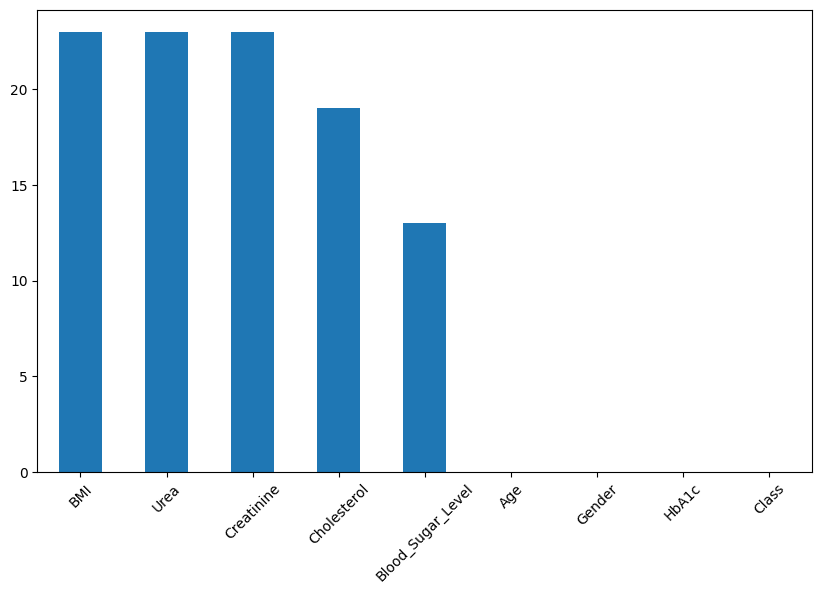

In [31]:
plt.figure(figsize=(10,6))
df.isna().sum().sort_values(ascending = False).plot(kind = 'bar')
plt.xticks(rotation = 45)
plt.show()

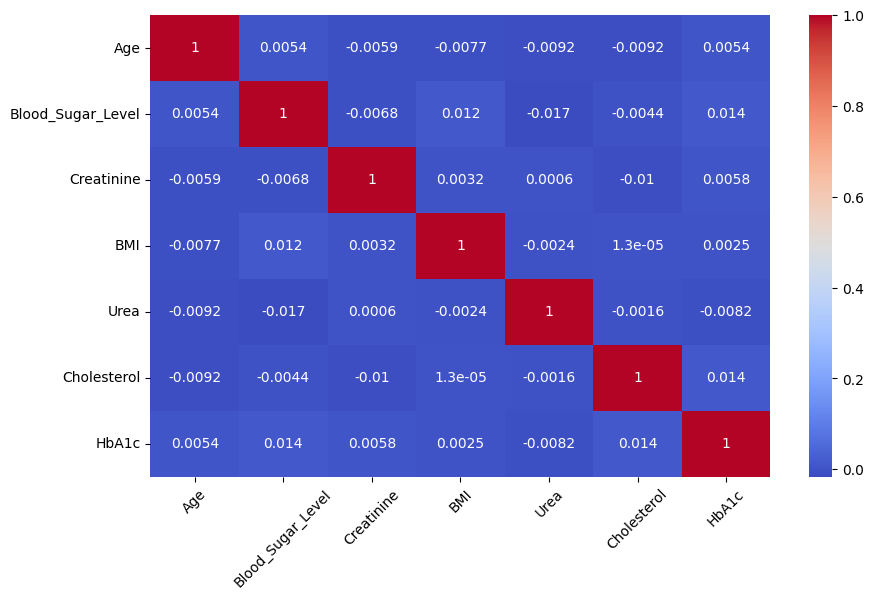

In [25]:
plt.figure(figsize = (10 ,6))
sns.heatmap(df.corr(numeric_only= True) ,annot = True ,cmap = 'coolwarm')
plt.xticks(rotation = 45)
plt.show()

In [33]:
ohe = ["Gender"]
scale = ["Age" ,  "Blood_Sugar_Level","Creatinine", "BMI", "Urea" , "Cholesterol", "HbA1c"]

In [57]:
numerical_pipline = Pipeline( steps = [
    ("imputer", SimpleImputer(strategy= "median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(
    steps = [

             ('imputer', SimpleImputer(strategy= "most_frequent")),
             ("encoder", OneHotEncoder(sparse_output=False , handle_unknown = "ignore"))
    ]
)

In [62]:
  preprocessor = ColumnTransformer(
      transformers = [
          ("num", numerical_pipline , scale),
          ("cat", categorical_pipeline , ohe)
      ],
          remainder="drop"

  )

In [63]:
X = df.drop('Class' , axis = 1)
y = df['Class']

In [64]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=.2 , random_state=1234)

In [65]:
X_train.shape

(7968, 8)

In [66]:
from sklearn.tree import DecisionTreeClassifier

In [67]:
pipline = Pipeline(steps = [
    ("preprocessor" , preprocessor),
    ("model" , DecisionTreeClassifier(random_state=42, class_weight="balanced"))
])

In [68]:
pipline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Blood_Sugar_Level',
                                                   'Creatinine', 'BMI', 'Urea',
                                                   'Cholesterol', 'HbA1c']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Gender'])])),
                ('model',
                 DecisionTreeClassifier(class_weight='balanced',
                                        random_state=42))])

In [72]:
pipline.score(X_train, y_train)

1.0

In [69]:
y_pred = pipline.predict(X_test)

In [71]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9994979919678715
              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1820
Non-Diabetic       1.00      0.99      1.00       172

    accuracy                           1.00      1992
   macro avg       1.00      1.00      1.00      1992
weighted avg       1.00      1.00      1.00      1992

[[1820    0]
 [   1  171]]


In [76]:
import pickle

# Train pipeline
pipline.fit(X_train, y_train)

# Save as Pickle
with open("diabetes_pipeline.pkl", "wb") as file:
    pickle.dump(pipline, file)

print("Model saved successfully!")

Model saved successfully!


In [77]:
with open("diabetes_pipeline.pkl", "rb") as file:
    loaded_model = pickle.load(file)

In [78]:
y_pred = loaded_model.predict(X_test)

In [82]:
import streamlit as st
import pandas as pd
import pickle
from pathlib import Path

# =========================
# Page Configuration
# =========================
st.set_page_config(
    page_title="Diabetes Prediction",
    page_icon="🩺",
    layout="wide"
)

# =========================
# Load Model
# =========================
@st.cache_resource
def load_model():
    with open("diabetes_pipeline.pkl", "rb") as file:
        return pickle.load(file)

try:
    model = load_model()
except FileNotFoundError:
    st.error("diabetes_pipeline.pkl not found!")
    st.stop()

# =========================
# Header
# =========================
st.title("🩺 Diabetes Prediction System")
st.markdown(
    "### Machine Learning Classification"
)
st.divider()

st.info(
    "Enter patient information to get a model prediction."
)

# =========================
# Patient Information
# =========================
st.subheader("Patient Information")

col1, col2 = st.columns(2)

with col1:
    age = st.number_input(
        "Age",
        min_value=1,
        max_value=120,
        value=30
    )

    gender = st.selectbox(
        "Gender",
        ["Male", "Female"]
    )

    blood_sugar = st.number_input(
        "Blood Sugar Level",
        min_value=0.0,
        value=100.0
    )

    creatinine = st.number_input(
        "Creatinine",
        min_value=0.0,
        value=1.0
    )

with col2:
    bmi = st.number_input(
        "BMI",
        min_value=0.0,
        value=25.0
    )

    urea = st.number_input(
        "Urea",
        min_value=0.0,
        value=30.0
    )

    cholesterol = st.number_input(
        "Cholesterol",
        min_value=0.0,
        value=180.0
    )

    hba1c = st.number_input(
        "HbA1c",
        min_value=0.0,
        value=5.5
    )

st.divider()

# =========================
# Prediction
# =========================
if st.button("🔍 Predict Diabetes Class", use_container_width=True):

    input_data = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Blood_Sugar_Level": blood_sugar,
        "Creatinine": creatinine,
        "BMI": bmi,
        "Urea": urea,
        "Cholesterol": cholesterol,
        "HbA1c": hba1c
    }])

    try:
        prediction = model.predict(input_data)[0]

        st.subheader("Prediction Result")

        st.success(f"Predicted Class: {prediction}")

        # Prediction probabilities
        if hasattr(model, "predict_proba"):

            probabilities = model.predict_proba(input_data)[0]

            probability_df = pd.DataFrame({
                "Class": model.classes_.astype(str),
                "Probability": probabilities
            })

            st.subheader("Prediction Probabilities")

            st.bar_chart(
                probability_df.set_index("Class")
            )

            st.dataframe(
                probability_df.style.format(
                    {"Probability": "{:.2%}"}
                ),
                use_container_width=True
            )

    except Exception as e:
        st.error(f"Prediction Error: {e}")

# =========================
# Footer
# =========================
st.divider()

st.caption(
    "Diabetes Prediction | Machine Learning Project"
)

st.warning(
    "Educational demonstration only. "
    "This application is not a medical diagnostic tool."
)

2026-10-31 16:07:29.503 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.505 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.506 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.507 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.509 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.510 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.511 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.512 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

In [84]:
pip install -r requirements.txt

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
